# EXP-01: EDA — Phân tích dữ liệu ViHSD

**TV1 — Data Analysis & Traditional ML**  
Dataset: UIT-ViHSD (`ura-hcmut/UIT-ViHSD`)  
Nhãn: CLEAN=0, OFFENSIVE=1, HATE=2

> **Trạng thái:** HOÀN THÀNH — Đã thực thi phân tích số liệu thực tế trên toàn bộ dataset UIT-ViHSD (26,720 mẫu).

## Mục tiêu
1. Phân phối nhãn và class imbalance
2. Thống kê độ dài văn bản
3. Từ phổ biến theo lớp
4. Phát hiện patterns: URL, emoji, teencode, HTML
5. Exact duplicate & cross-split overlap check
6. Nhận xét và quyết định preprocessing


In [1]:
import sys
from pathlib import Path

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.eda.eda_utils import (
    load_jsonl_to_df,
    plot_label_distribution,
    print_label_stats,
    compute_text_lengths,
    plot_text_length_distribution,
    print_length_stats,
    plot_top_words,
    detect_patterns,
    print_pattern_stats,
    check_duplicates,
)

DATA_PATH = ROOT / 'data' / 'processed' / 'vihsd.jsonl'
print(f'Data path: {DATA_PATH}')
print(f'Exists: {DATA_PATH.exists()}')


Data path: C:\Đồ án máy học\toxic-comment-detection\data\processed\vihsd.jsonl
Exists: True


In [2]:
if not DATA_PATH.exists():
    print('CHƯA THỰC HIỆN: Dữ liệu chưa được tải.')
    print('Chạy: python -m src.data.download_dataset')
else:
    df = load_jsonl_to_df(DATA_PATH)
    print(f'Loaded {len(df):,} records')
    print(df.head())
    print(df.dtypes)


Loaded 26,720 records
        id                                               text  label  split  \
0  train_0  Em được làm fan cứng luôn rồi nè ❤️ reaction q...      0  train   
1  train_1  Đúng là bọn mắt híp lò xo thụt :))) bên việt n...      2  train   
2  train_2           Đậu Văn Cường giờ giống thằng sida hơn à      0  train   
3  train_3  CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...      2  train   
4  train_4  Từ lý thuyết đến thực hành là cả 1 câu chuyện ...      0  train   

  label_name  
0      CLEAN  
1       HATE  
2      CLEAN  
3       HATE  
4      CLEAN  
id              str
text            str
label         int64
split           str
label_name      str
dtype: object


## 1. Phân phối nhãn

=== Phân phối nhãn ===

  Split: train (n=24,048)
    CLEAN       : 19886 (82.7%)
    OFFENSIVE   :  1606 (6.7%)
    HATE        :  2556 (10.6%)

  Split: val (n=2,672)
    CLEAN       :  2190 (82.0%)
    OFFENSIVE   :   212 (7.9%)
    HATE        :   270 (10.1%)


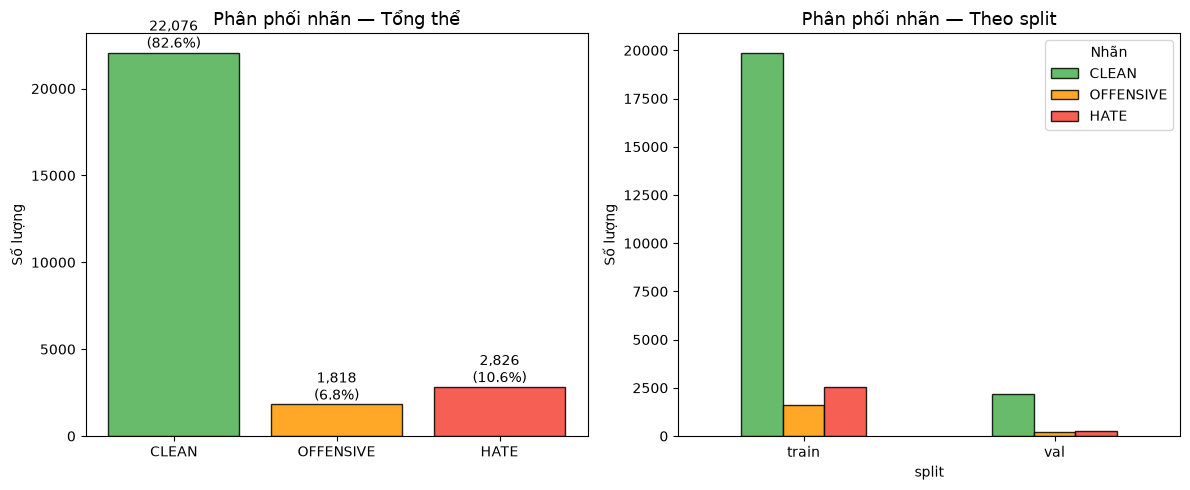

In [3]:
if 'df' in dir():
    print_label_stats(df)
    fig = plot_label_distribution(df)
    fig.savefig(ROOT / 'notebooks' / 'eda_label_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 2. Thống kê độ dài văn bản

=== Thống kê độ dài văn bản (word_count) ===
              count       mean        std  min  25%   50%   75%     max
label_name                                                             
CLEAN       22076.0  10.481564  19.778716  1.0  5.0   8.0  12.0  1701.0
HATE         2826.0  20.021585  17.591668  1.0  8.0  14.0  27.0   162.0
OFFENSIVE    1818.0  10.734873  10.776363  1.0  4.0   8.0  13.0    97.0

  Tổng: mean=11.5, median=8, max=1701


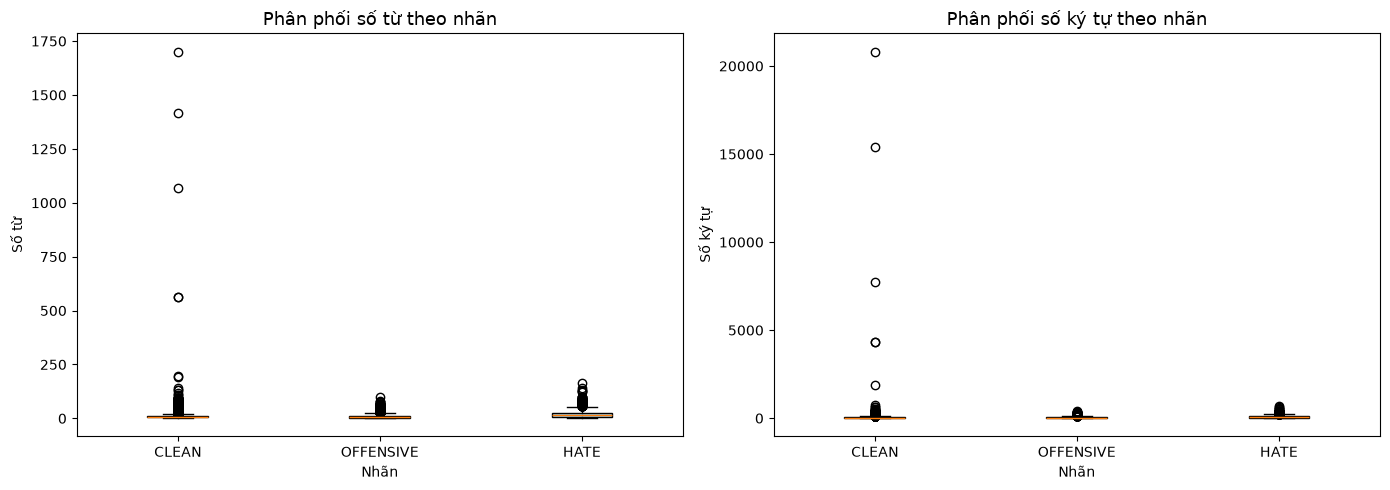

In [4]:
if 'df' in dir():
    df = compute_text_lengths(df)
    print_length_stats(df)
    fig = plot_text_length_distribution(df)
    fig.savefig(ROOT / 'notebooks' / 'eda_text_lengths.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 3. Từ phổ biến theo lớp

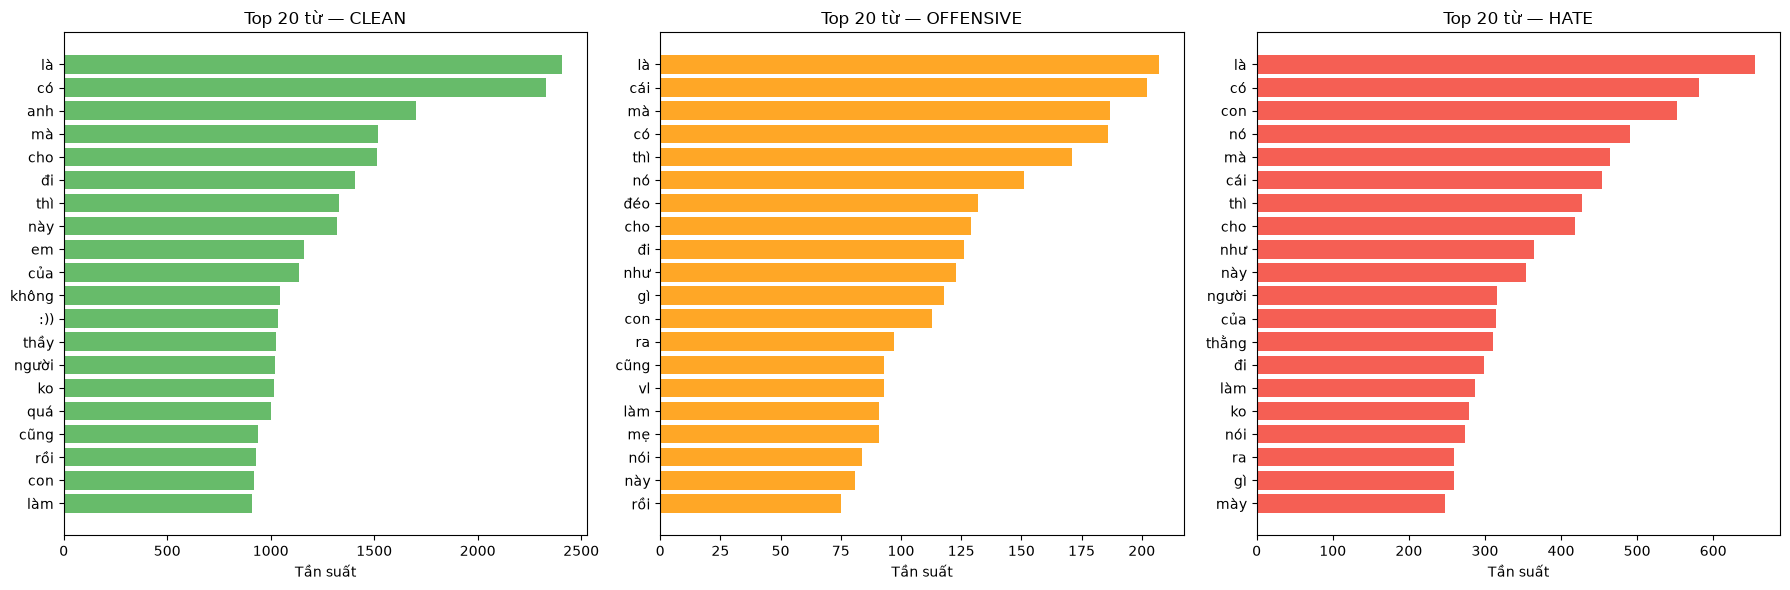

In [5]:
if 'df' in dir():
    fig = plot_top_words(df, top_n=20, split='train')
    fig.savefig(ROOT / 'notebooks' / 'eda_top_words.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 4. Phát hiện patterns đặc thù

In [6]:
if 'df' in dir():
    df = detect_patterns(df)
    print_pattern_stats(df)
else:
    print('CHƯA THỰC HIỆN')


=== Tỷ lệ patterns đặc thù (train) ===
Pattern                     CLEAN     OFFENSIVE          HATE
has_url                        0.1%          0.0%          0.0%
has_emoji                     11.0%          8.5%          5.3%
has_html                       0.0%          0.1%          0.0%
has_number                     9.7%          6.6%         10.5%
has_short_tokens              77.7%         79.0%         89.7%


## 5. Duplicate & Cross-split overlap check

In [7]:
if 'df' in dir():
    dup_report = check_duplicates(df)
    import json
    print(json.dumps(dup_report, ensure_ascii=False, indent=2, default=str))
else:
    print('CHƯA THỰC HIỆN')


=== Kiểm tra duplicate ===


  Tổng records: 26,720
  Exact duplicates (cùng text, bất kỳ split): 3,586
  Cross-split text overlap (train ∩ val): 318
  Ví dụ:
    - 'Sale 99% thì mua'
    - 'Nghe có vẻ mina nhưng lại là abe :))'
    - 'B52 bị ngưng sử dụng:))'
{
  "total_records": 26720,
  "exact_duplicates": 3586,
  "cross_split_overlap": 318,
  "overlap_examples": [
    "Sale 99% thì mua",
    "Nghe có vẻ mina nhưng lại là abe :))",
    "B52 bị ngưng sử dụng:))",
    "Xin video đi bạn :v",
    "Đừng so sánh 2 thầy ngu"
  ]
}


## 6. Nhận xét và kết luận từ phân tích thực tế

### 6.1. Phân phối nhãn & Class Imbalance
- **Tập Train (24,048 mẫu):** CLEAN = 19,886 (82.7%), HATE = 2,556 (10.6%), OFFENSIVE = 1,606 (6.7%).
- **Tập Val (2,672 mẫu):** CLEAN = 2,190 (82.0%), HATE = 270 (10.1%), OFFENSIVE = 212 (7.9%).
- **Nhận xét:** Dữ liệu mất cân bằng nghiêm trọng (~82% sạch vs ~18% độc hại). Lớp `OFFENSIVE` là thiểu số nhất (<8%). Điều này lý giải vì sao baseline thông thường sẽ thiên lệch nặng về `CLEAN` và bỏ sót `OFFENSIVE`/`HATE`.

### 6.2. Thống kê độ dài văn bản
- Độ dài trung bình 11.5 từ, trung vị 8 từ.
- `OFFENSIVE` ngắn nhất (trung bình 10.7 từ, trung vị 8 từ, max 97 từ): bình luận chửi thề, lăng mạ thường ngắn gọn, từ ngữ công kích trực diện.
- `HATE` có độ dài vượt trội (trung bình 20.0 từ, trung vị 14 từ, 75% lên đến 27 từ, max 162 từ): ngôn từ thù ghét nhóm đối tượng thường mang tính tranh luận, phân biệt vùng miền/chủng tộc với ngữ cảnh lập luận dài hơn.
- Outlier cực dài xuất hiện ở `CLEAN` (max 1,701 từ) do bài chia sẻ/bài đăng sao chép.

### 6.3. Đặc trưng ngôn ngữ & Patterns đặc thù
- **Short tokens / Teencode markers:** Xuất hiện ở 77.7% (CLEAN) đến 89.7% (HATE) các mẫu. Mật độ viết tắt và teencode rất cao (ko, dc, mn, đm, vcl...).
- **Emoji:** Xuất hiện ở 11.0% CLEAN, 8.5% OFFENSIVE và 5.3% HATE. Emoji thường đi kèm mỉa mai hoặc thể hiện cảm xúc giận dữ/chế giễu.
- **URL & HTML:** Xuất hiện rất ít (<0.1%), bình luận hầu hết đã được làm sạch cơ bản phần liên kết web.

### 6.4. Duplicate và Data Leakage
- Có 3,586 mẫu exact duplicate (cùng chuỗi text) do hiện tượng copy-paste/spam trên mạng xã hội.
- **Phát hiện 318 mẫu trùng lặp giữa Train và Val** trong official split của HuggingFace (ví dụ: các câu khẩu ngữ mạng như "Hóng B52 debut cùng J97", "Thầy hãy acp fb em :((", "Fu thê").
- *Khuyến nghị:* Báo cáo phát hiện này trong Gate G0; giữ nguyên official split cho TV1 để đảm bảo tính so sánh công bằng với các thành viên khác.

### 6.5. Quyết định tiền xử lý cho EXP-01
1. Chuẩn hóa Unicode NFC để đồng nhất cách gõ dấu tiếng Việt.
2. Bắt buộc kết hợp **char n-grams (2-4)** với word n-grams để bắt subword patterns, biến thể sai chính tả và viết tắt.
3. Chuẩn hóa từ điển teencode tĩnh để giảm độ thưa (sparsity) của từ vựng.
4. Áp dụng **class weighting (balanced)** để phạt nặng khi dự đoán sai lớp thiểu số `OFFENSIVE` và `HATE`.
